## Финальный проект

#### *«Я чувствую себя как функция арктангенса, которая приближается к асимптоте.» — Теория большого взрыва*

Это финальный проект продуктового блока курса «Продуктовые метрики». За него можно получить максимум 60 баллов. 

**Дедлайны**   
Жесткий дедлайн: 25.10.2026 23:59 по МСК. 

После жесткого дедлайна работы не принимаются. 

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание аннулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например final_project). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/final_project_data.zip)

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import requests

from statsmodels.tsa.seasonal import STL
from scipy.stats import norm
from scipy.stats import t
import math

import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns

### Case Study. Улучшение сервиса доставки из ресторанов 🌮

**Легенда**   
Вы присоединились к продуктовой команде сервиса доставки из ресторанов в роли аналитика. Близится планирование следующего квартала, пора готовить бэклог инициатив. Продакт-менеджер особенно беспокоится об удовлетворенности пользователей — за последний месяц выросло число отмен и жалоб на задержки.

Вам поставлена задача: провести исследование текущих значений метрик, выдвинуть гипотезу о проблеме и предложить её решение.

In [2]:
df = pd.read_csv('data/final_project_delivery.csv')

df.head()

,order_id,order_time,delivery_time,status,cancellation_reason,order_value,delivery_fee,estimated_delivery_time_min,time_to_assign_courier_min,actual_preparation_time_min,travel_time_min,delivery_distance_km,promotion_used,platform,city_region,user_id,user_segment
0,257,2022-11-01 00:01:46,2022-11-01 00:21:52,delivered,NaN,25.73,2.09,27.0,10.2,15.1,5.0,3.48,no,Android,Belem,5737,returning
1,165,2022-11-01 00:06:07,2022-11-01 00:27:01,delivered,NaN,22.00,0.77,13.0,9.0,15.9,5.0,1.29,no,iOS,Parque das Nacoes,4095,new
2,343,2022-11-01 21:07:01,2022-11-01 21:40:07,delivered,NaN,29.90,3.53,44.0,10.6,15.4,15.1,5.88,no,iOS,Parque das Nacoes,15991,returning
3,904,2022-11-01 00:06:48,2022-11-01 00:36:42,delivered,NaN,40.49,2.02,27.0,3.7,16.0,13.9,3.36,no,Android,Alfama,1773,returning
4,555,2022-11-01 00:09:58,2022-11-01 00:57:22,delivered,NaN,35.75,3.48,39.0,5.2,12.3,35.1,5.80,no,iOS,Baixa,5203,returning


Описание данных:

- order_id — уникальный идентификатор заказа
- order_time — timestamp создания заказа
- delivery_time – timestamp доставки заказа
- status — статус заказа, принимает 2 значения: delivered и cancelled
- cancellation_reason — причина отмены заказа: Cancelled by user (отменена пользователем) и No courier available (нет доступных курьеров)
- order_value — стоимость заказа
- delivery_fee — стоимость доставки
- estimated_delivery_time_min — прогнозное время доставки
- time_to_assign_courier_min — время до назначения курьера
- actual_preparation_time_min — время приготовления заказа рестораном
- travel_time_min — суммарное время на дорогу курьера до ресторана и до конечного пользователя
- delivery_distance_km — расстояние от адреса доставки до адреса ресторана
- promotion_used — был ли заказ совершен с использованием промокода или акции
- platform — платформа, с которой совершен заказ
- city_region — район города, в который планируется доставка
- user_id — уникальный идентификатор пользователя, сделавшего заказ
- user_segment — сегмент пользователя (новый или вернувшийся)    

### Часть 1. Исследование

#### 1. Динамика основных метрик — 3 балла
Рассчитайте и визуализируйте по дням:
- Число заказов, число доставленных заказов (статус delivered);
- Completion Rate (Доставленные заказы / Все заказы), Cancellation Rate (Отмененные заказы / Все заказы);
- Среднее и медианное время доставки в минутах (рассчитывается как разница между delivery_time и order_time), средний чек заказа, среднюю стоимость доставки.

Сделайте выводы:
- Есть ли выраженный тренд?
- Может быть какие-то дни кажутся подозрительными на предмет аномалий?

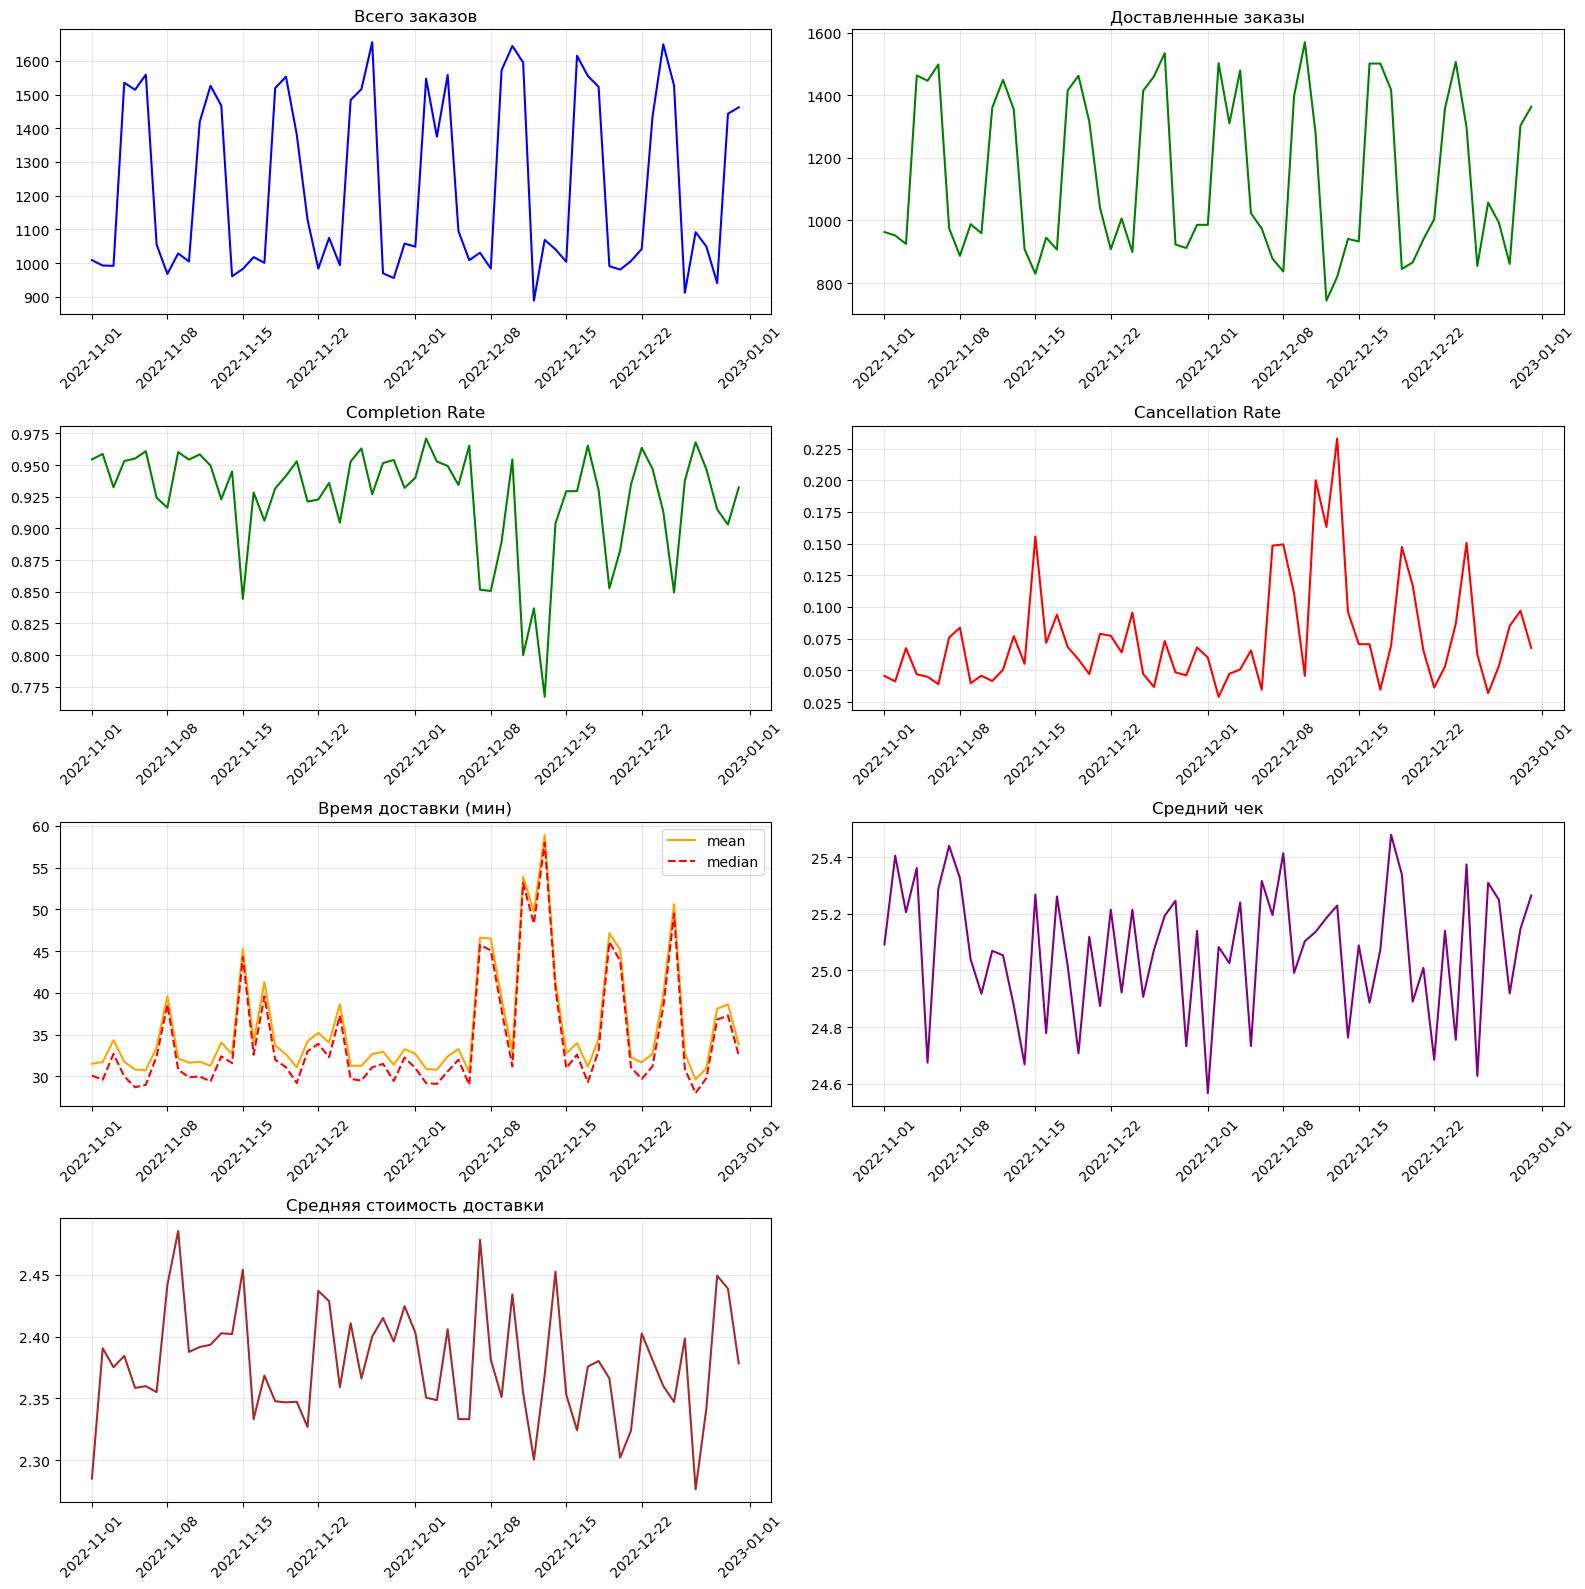

         date  total_orders  delivered_orders  avg_delivery_time  \
0  2022-11-01          1009               963          31.517445   
1  2022-11-02           993               952          31.725630   
2  2022-11-03           992               925          34.353622   
3  2022-11-04          1535              1463          31.755707   
4  2022-11-05          1514              1446          30.828907   

   median_delivery_time  avg_order_value  avg_delivery_fee  completion_rate  \
0                  30.1        25.091615          2.284965         0.954410   
1                  29.6        25.404552          2.390564         0.958711   
2                  32.7        25.205383          2.375252         0.932460   
3                  30.0        25.361316          2.384384         0.953094   
4                  28.7        24.674485          2.358448         0.955086   

   cancellation_rate  
0           0.045590  
1           0.041289  
2           0.067540  
3           0.046906  
4

In [3]:
# your code is here
df['order_time'] = pd.to_datetime(df['order_time'])
df['delivery_time'] = pd.to_datetime(df['delivery_time'])
df['date'] = df['order_time'].dt.date
df['delivery_time_min'] = (df['delivery_time'] - df['order_time']).dt.total_seconds() / 60
daily = df.groupby('date').agg(
    total_orders=('order_id', 'count'),
    delivered_orders=('status', lambda x: (x == 'delivered').sum()),
    avg_delivery_time=('delivery_time_min', 'mean'),
    median_delivery_time=('delivery_time_min', 'median'),
    avg_order_value=('order_value', 'mean'),
    avg_delivery_fee=('delivery_fee', 'mean')
).reset_index()
daily['completion_rate'] = daily['delivered_orders'] / daily['total_orders']
daily['cancellation_rate'] = 1 - daily['completion_rate']
fig, axes = plt.subplots(4, 2, figsize=(16, 16))
axes[0, 0].plot(daily['date'], daily['total_orders'], color='blue')
axes[0, 0].set_title('Всего заказов')
axes[0, 1].plot(daily['date'], daily['delivered_orders'], color='green')
axes[0, 1].set_title('Доставленные заказы')
axes[1, 0].plot(daily['date'], daily['completion_rate'], color='green')
axes[1, 0].set_title('Completion Rate')
axes[1, 1].plot(daily['date'], daily['cancellation_rate'], color='red')
axes[1, 1].set_title('Cancellation Rate')
axes[2, 0].plot(daily['date'], daily['avg_delivery_time'], color='orange', label='mean')
axes[2, 0].plot(daily['date'], daily['median_delivery_time'], color='red', linestyle='--', label='median')
axes[2, 0].set_title('Время доставки (мин)')
axes[2, 0].legend()
axes[2, 1].plot(daily['date'], daily['avg_order_value'], color='purple')
axes[2, 1].set_title('Средний чек')
axes[3, 0].plot(daily['date'], daily['avg_delivery_fee'], color='brown')
axes[3, 0].set_title('Средняя стоимость доставки')
axes[3, 1].axis('off')
for ax in axes.flatten()[:-1]:
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(daily.head())

## Выоды 1.1.
Выраженной долгосрочной тенденции - нет. Однако, стоит отметить, что в выходные дни число заказов выше, чем в будни.

13-14 ноября и 9-10 декабря — именно в эти даты провалилась конверсия и выросло время доставки. Это выглядит как явная аномалия, стоит глубже в ней покопаться, возхможно там были какие-то логистический проблемы или проблема с поставками/работниками (F работникам) 

#### 2. Выявление аномалий — 3 балла
Проверьте построенные дневные ряды следующих метрик на аномальность:
- Число заказов, число доставленных заказов;
- Completion Rate, Cancellation Rate;
- Время доставки (среднее и медиана).

Для метрик, в которых визуально заметна недельная сезонность (абсолютные метрики), используйте STL-разложение + 3σ, для других — просто 3σ (вы проводите ретроспективный анализ, а не имитируете онлайн-проверку, не забывайте об этом в реализации).

Дайте короткий комментарий по результатам проверки.

In [6]:
# your code is here
def detect_anomalies_stl(series, period=7):
    stl = STL(series, period=period)
    res = stl.fit()
    resid = res.resid
    mean = resid.mean()
    std = resid.std()
    anomalies = (resid > mean + 3 * std) | (resid < mean - 3 * std)
    return anomalies
def detect_anomalies_3sigma(series):
    mean = series.mean()
    std = series.std()
    anomalies = (series > mean + 3 * std) | (series < mean - 3 * std)
    return anomalies
daily = daily.sort_values('date').reset_index(drop=True)
for m in ['total_orders', 'delivered_orders']:
    anom = detect_anomalies_stl(daily[m])
    print(f"{m}: {daily['date'][anom].tolist()}")
for m in ['completion_rate', 'cancellation_rate', 'avg_delivery_time', 'median_delivery_time']:
    anom = detect_anomalies_3sigma(daily[m])
    print(f"{m}: {daily['date'][anom].tolist()}")

total_orders: []
delivered_orders: []
completion_rate: [datetime.date(2022, 12, 13)]
cancellation_rate: [datetime.date(2022, 12, 13)]
avg_delivery_time: [datetime.date(2022, 12, 13)]
median_delivery_time: [datetime.date(2022, 12, 13)]


## Вывод 1.2
Кртко аномалия по ретроспективному анализу - одна, 13-ое декабря, хотя графики до этого тоже были старнные, но ладно... 

#### 3. Поиск причин аномального поведения (шаг 1) — 3 балла
Разложим метрики, в которых обнаружены аномалии, на составляющие.

Визуализируйте:
- Отмены в разрезе причин (абсолютная метрика);
- Длительность этапов, из которых складывается итоговая продолжительность доставки (time_to_assign_courier_min, actual_preparation_time_min, travel_time_min). Берите среднее или медиану на ваш выбор.

Есть ли какие-нибудь закономерности?

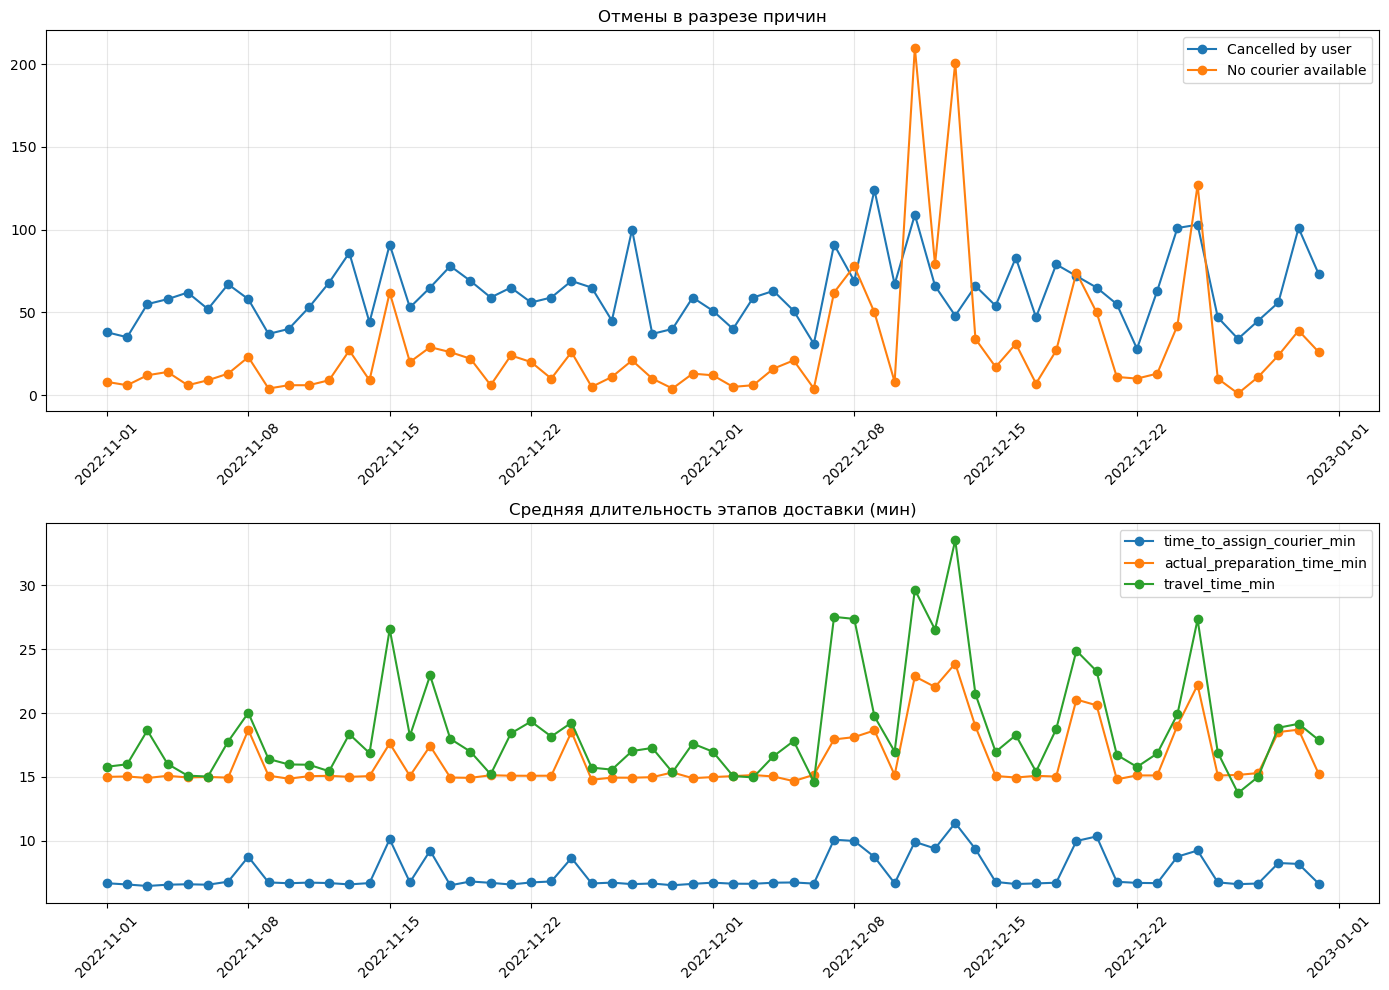

Отмены в разрезе причин (топ-5 дней):
cancellation_reason        date  Cancelled by user  No courier available
38                   2022-12-09                124                    50
40                   2022-12-11                109                   210
54                   2022-12-25                103                   127
53                   2022-12-24                101                    42
59                   2022-12-30                101                    39


In [7]:
# your code is here
df['date'] = pd.to_datetime(df['order_time']).dt.date
cancelled = df[df['status'] == 'cancelled']
cancel_by_reason = cancelled.groupby(['date', 'cancellation_reason']).size().unstack(fill_value=0).reset_index()
cancel_by_reason = cancel_by_reason.sort_values('date')
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
for col in cancel_by_reason.columns:
    if col != 'date':
        axes[0].plot(cancel_by_reason['date'], cancel_by_reason[col], marker='o', label=col)
axes[0].set_title('Отмены в разрезе причин')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()
axes[0].grid(True, alpha=0.3)
daily_steps = df.groupby('date')[['time_to_assign_courier_min', 'actual_preparation_time_min', 'travel_time_min']].mean().reset_index()
daily_steps = daily_steps.sort_values('date')
for col in ['time_to_assign_courier_min', 'actual_preparation_time_min', 'travel_time_min']:
    axes[1].plot(daily_steps['date'], daily_steps[col], marker='o', label=col)
axes[1].set_title('Средняя длительность этапов доставки (мин)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("Отмены в разрезе причин (топ-5 дней):")
print(cancel_by_reason.sort_values(cancel_by_reason.columns[1], ascending=False).head())

## Вывод 1.3
Как мы видим, основной вклад в нашу аномалию вызвал резкий всплеск отмены заказов Пик - 11 декабря (210 шт. (вы че там совсем, че так много) 

Также можно отметить, что с время в пути увеличилось с 8-го декабря (ЗНАЧИТЕЛЬНО), собственно, это также один из критериев. Если предположить в рамках нашей реальности, условную дорогу X разрушили паводки или еще что-то, людям было не до доставок и они поотменяли заказы, а те кто оставил заказ, долго ждали доставку, ибо основной маршрут почил в дорожный рай. 

#### 4. Поиск причин аномального поведения (шаг 2) — 3 балла
Постройте динамику метрик, в которых обнаружены аномалии, по базовым срезам (можете выбрать что-то одно: Completion Rate или Cancellation Rate, среднее время доставки или медиана времени доставки):
- платформа (iOS, Android);
- район адреса доставки;
- сегмент пользователя (новые / повторные);
- признак промо акции.

Выделяется ли какой-то сегмент, где аномалия выражена сильнее?

C:\Users\Михаил\AppData\Local\Temp\ipykernel_18172\2177938910.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cr = df.groupby(['date', col]).apply(lambda x: (x['status'] == 'delivered').mean()).reset_index(name='completion_rate')
C:\Users\Михаил\AppData\Local\Temp\ipykernel_18172\2177938910.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cr = df.groupby(['date', col]).apply(lambda x: (x['status'] == 'delive

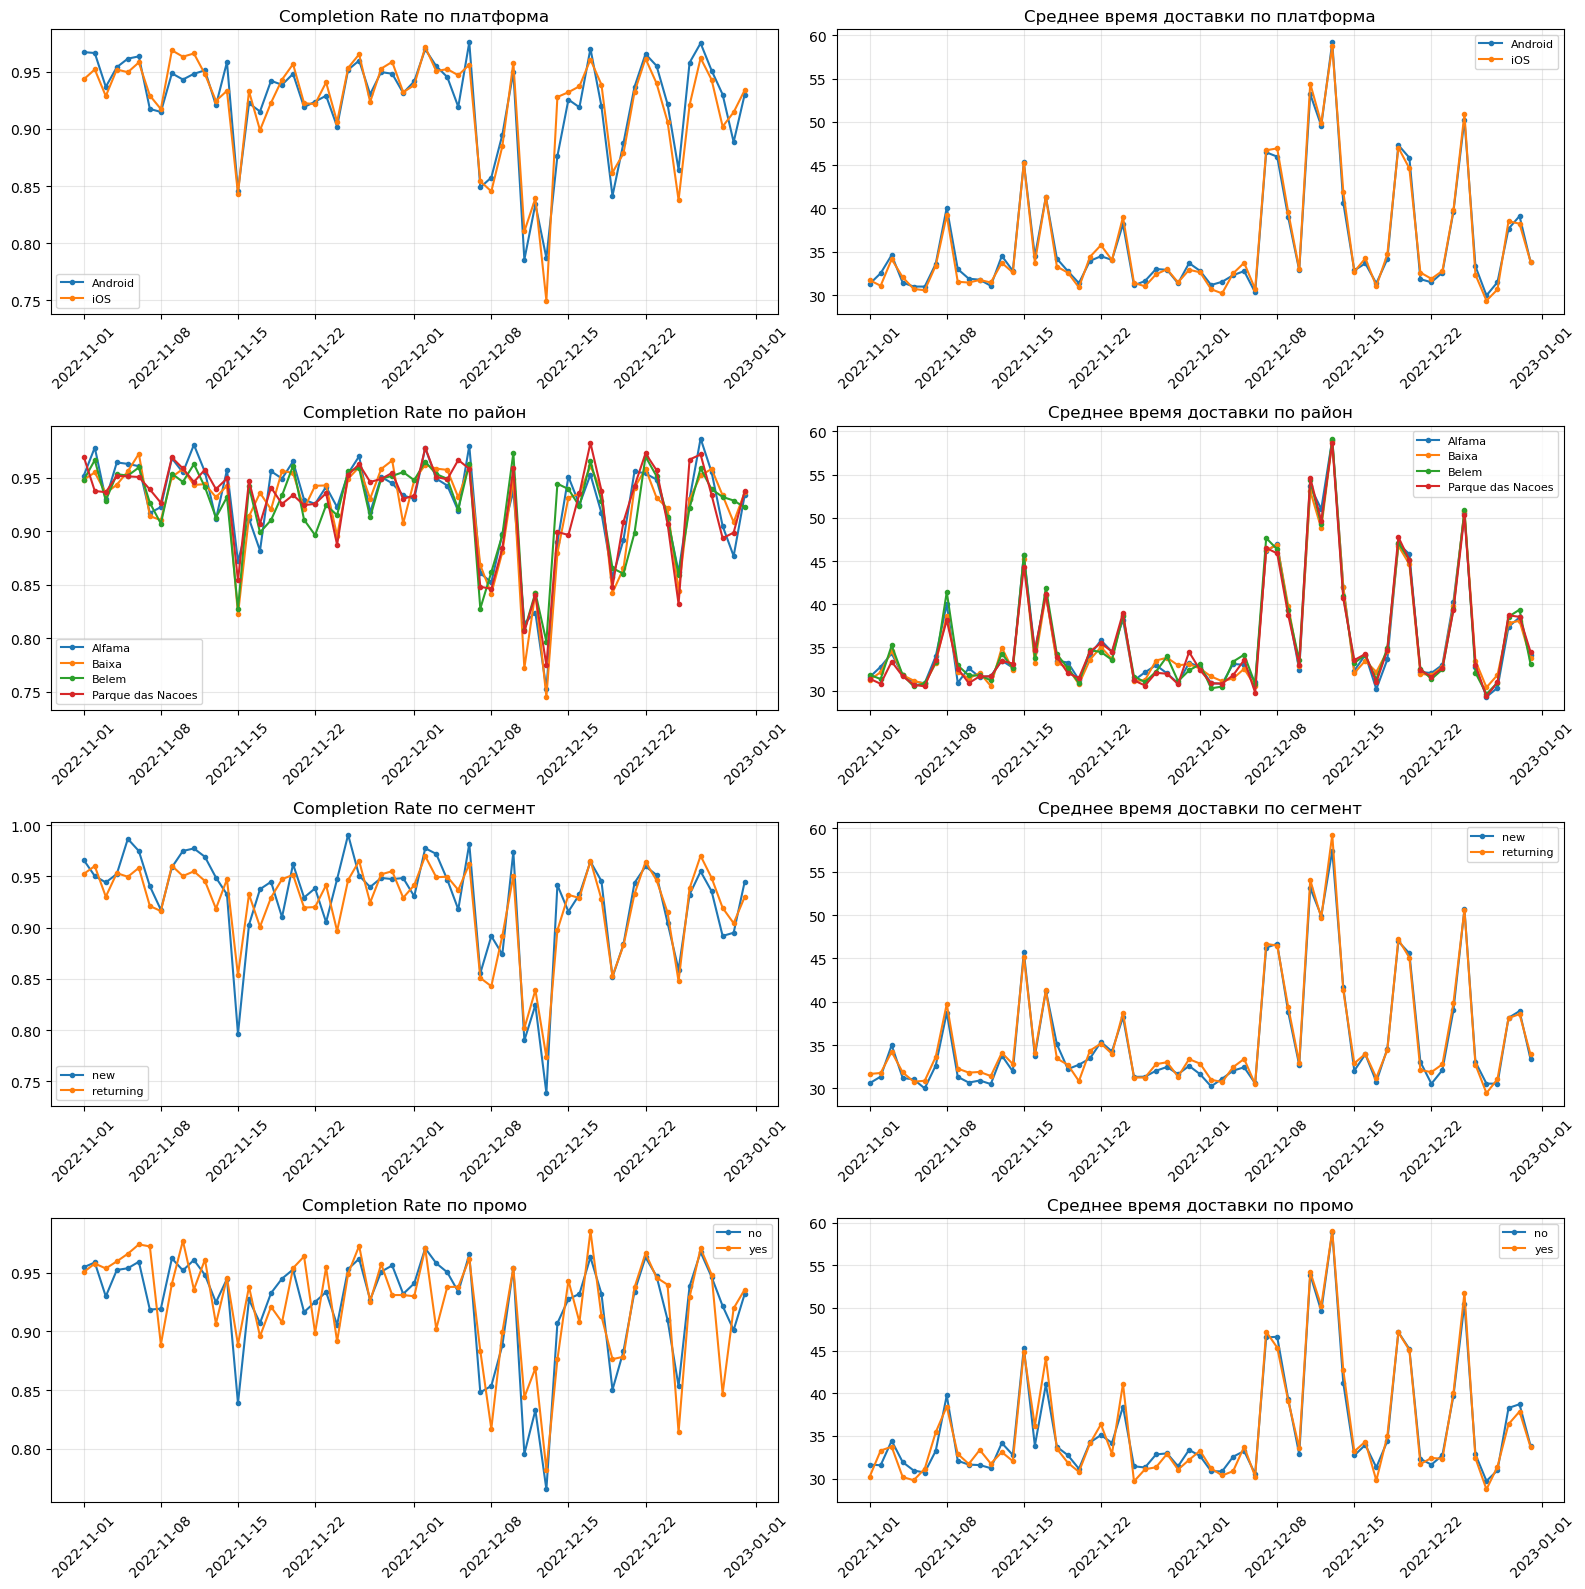

In [8]:
# your code is here
fig, axes = plt.subplots(4, 2, figsize=(16, 16))
slices = [
    ('platform', 'Платформа'),
    ('city_region', 'Район'),
    ('user_segment', 'Сегмент'),
    ('promotion_used', 'Промо')
]
for i, (col, title) in enumerate(slices):
    cr = df.groupby(['date', col]).apply(lambda x: (x['status'] == 'delivered').mean()).reset_index(name='completion_rate')
    cr = cr.sort_values('date')
    for val in cr[col].unique():
        subset = cr[cr[col] == val]
        axes[i, 0].plot(subset['date'], subset['completion_rate'], marker='.', label=str(val))
    axes[i, 0].set_title(f'Completion Rate по {title.lower()}')
    axes[i, 0].tick_params(axis='x', rotation=45)
    axes[i, 0].legend(fontsize=8)
    axes[i, 0].grid(True, alpha=0.3)
    deliv = df[df['status'] == 'delivered'].groupby(['date', col])['delivery_time_min'].mean().reset_index()
    deliv = deliv.sort_values('date')
    for val in deliv[col].unique():
        subset = deliv[deliv[col] == val]
        axes[i, 1].plot(subset['date'], subset['delivery_time_min'], marker='.', label=str(val))  
    axes[i, 1].set_title(f'Среднее время доставки по {title.lower()}')
    axes[i, 1].tick_params(axis='x', rotation=45)
    axes[i, 1].legend(fontsize=8)
    axes[i, 1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Вывод 1.4. 

ПО ПУНКТИКАМ
1. Аномалия затронула обе платформы (моя идея про дорогу пока жива)
2. Все районы (Ну допустим главное шоссе города, хотя вот тут уже дорога потихоньку отваливается)
3. Сегменты, Все одинаково
4. Промо никак не влияет.

Если обобщать, проблема - общая

#### 5. Поиск причин аномального поведения (шаг 3) — 3 балла

Постройте динамику структуры заказов в разрезе сегментов:
- доля заказов по платформам;
- доля заказов по регионам города;
- доля заказов по сегменту пользователя;
- доля заказов по признаку промо акции.

Сравните даты аномалий с динамикой долей. Может ли изменение структуры объяснить падение метрик?

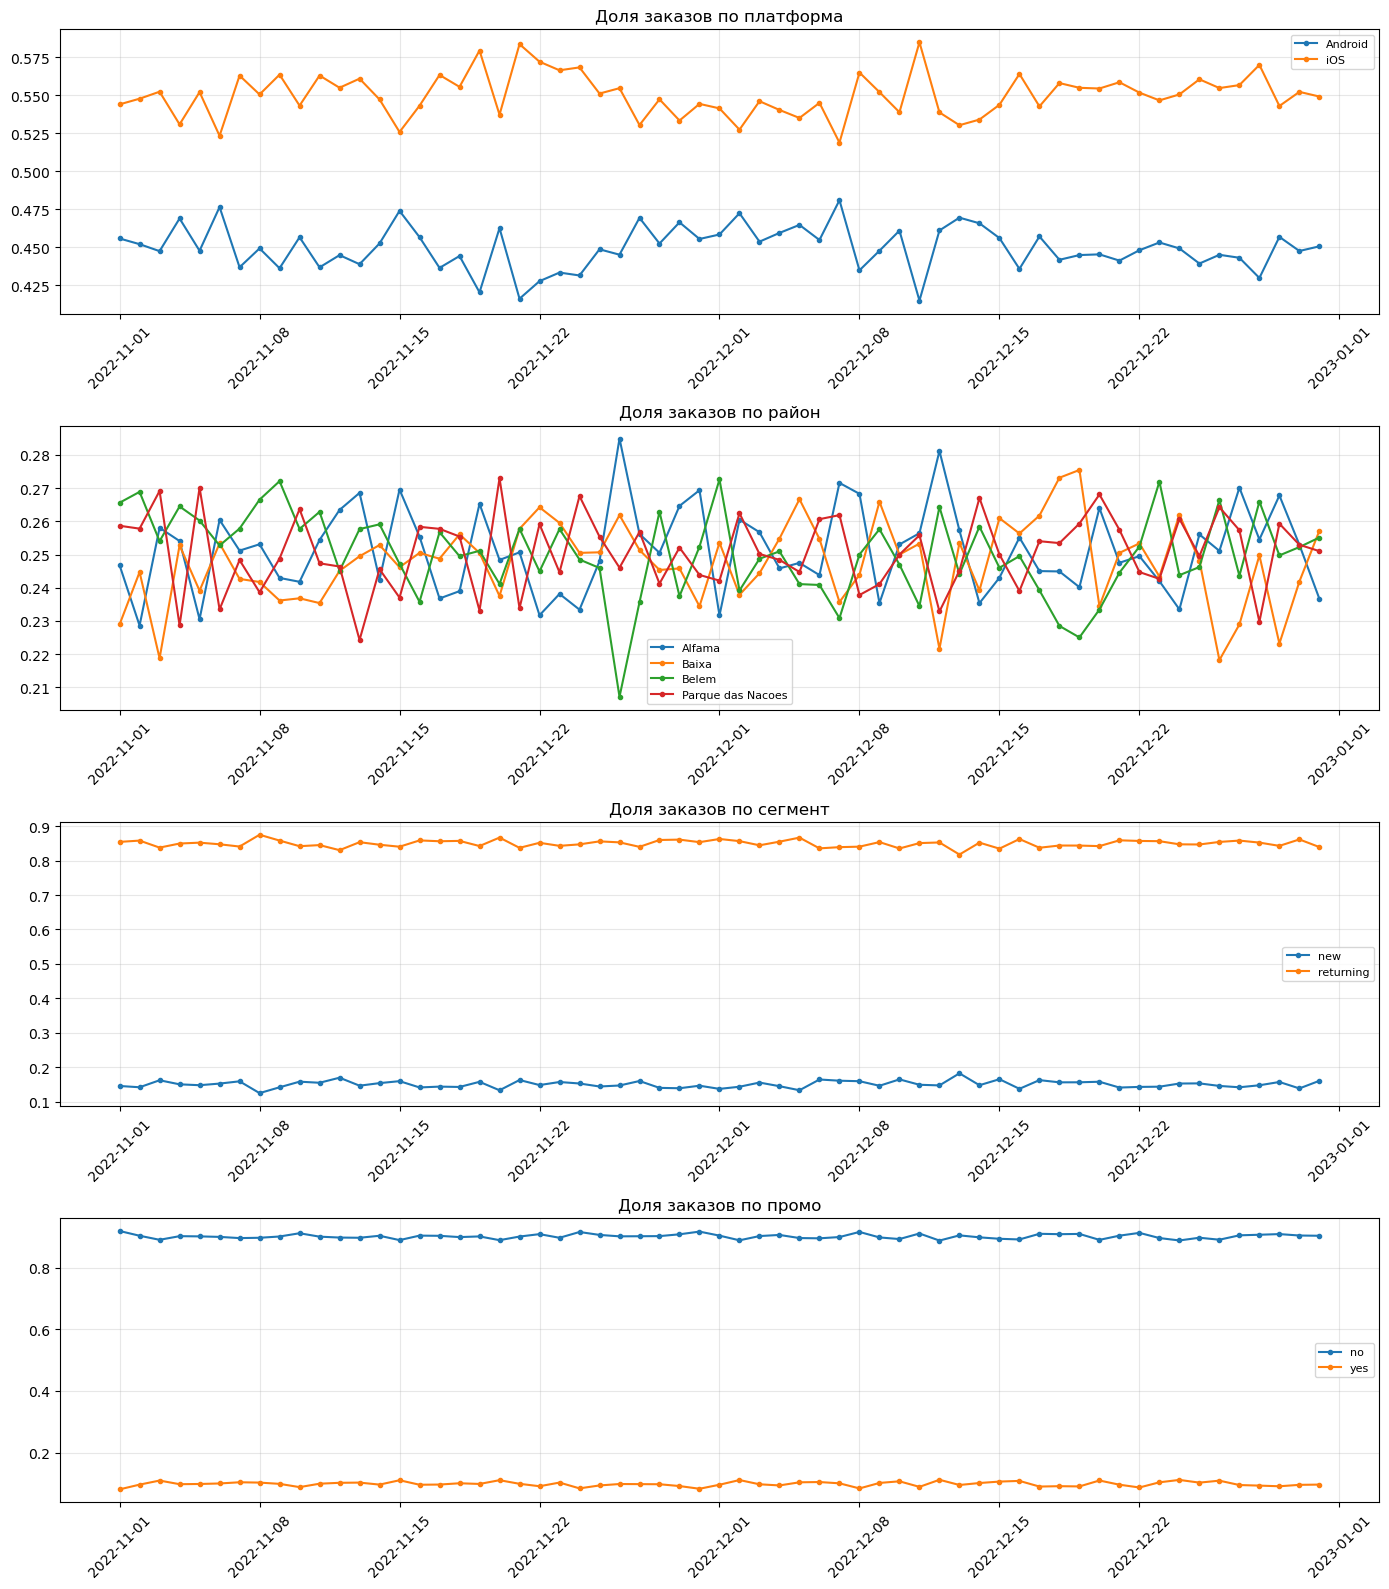

In [9]:
# your code is here
fig, axes = plt.subplots(4, 1, figsize=(14, 16))
slices = [
    ('platform', 'Платформа'),
    ('city_region', 'Район'),
    ('user_segment', 'Сегмент'),
    ('promotion_used', 'Промо')
]
for i, (col, title) in enumerate(slices):
    shares = df.groupby(['date', col]).size().unstack(fill_value=0)
    shares = shares.div(shares.sum(axis=1), axis=0)
    shares = shares.reset_index()
    shares = shares.sort_values('date')
    for c in shares.columns:
        if c != 'date':
            axes[i].plot(shares['date'], shares[c], marker='.', label=str(c))  
    axes[i].set_title(f'Доля заказов по {title.lower()}')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(fontsize=8)
    axes[i].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Выводы 1.5

1. По платформам всё =- ровно, за исключением нашего периода, там провал у андроид устройств и рост у яблочников (прям как...)
2. Вот по районам веселее, помню про еще 1-н полуаномальный период в ноябре и вот как раз там, рост альфрамы и паденее беляша белем-а. Так же в наш период аналогичные события, но в целом сегмент +- ровненикий
3. Мне даже говорить нечего, дажэе 1-о классник видит, что тут все ок
4. аналогично

#### 6. Поиск причин аномального поведения (шаг 4) — 3 балла
Разложение метрик на срезы не принесло результатов. Может быть причина аномалий лежит вне продукта?

Получите данные о погоде по API за весь анализируемый период по дням. Для этого используйте [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api?daily=temperature_2m_mean,wind_speed_10m_max,precipitation_sum) от Open-Meteo (регистрация и получение ключа не требуется, по ссылке есть пример запроса на Python).

- Для координат выгрузки возьмите: latitude: 38.736946, longitude: -9.142685;
- Timezone — auto;
- daily значения temperature_2m_mean, precipitation_sum, wind_speed_10m_max.

Соберите датасет с колонками: день, средняя температура воздуха, максимальная скорость ветра, суммарное количество осадков.

In [10]:
# your code is here

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 38.736946,
    "longitude": -9.142685,
    "start_date": "2022-11-01",
    "end_date": "2022-12-31",
    "daily": ["temperature_2m_mean", "precipitation_sum", "wind_speed_10m_max"],
    "timezone": "auto"
}
response = requests.get(url, params=params)
weather_data = response.json()
df_weather = pd.DataFrame({
    'date': pd.to_datetime(weather_data['daily']['time']).date,
    'temp_mean': weather_data['daily']['temperature_2m_mean'],
    'precipitation': weather_data['daily']['precipitation_sum'],
    'wind_speed_max': weather_data['daily']['wind_speed_10m_max']
})
print(df_weather.head())

         date  temp_mean  precipitation  wind_speed_max
0  2022-11-01       15.8            0.0            16.1
1  2022-11-02       14.8            0.0            14.8
2  2022-11-03       17.5            4.2            23.1
3  2022-11-04       15.8            0.0            15.5
4  2022-11-05       14.1            0.0             9.7


Наших дат .нет, ща буим соеденять 

#### 7. Поиск причин аномального поведения (шаг 5) — 3 балла
Объедините датасет метрик, в которых найдены аномалии, с датасетом погоды.    
Для каждой метрики постройте совместные визуализации данных погоды и продуктовой метрики.

Сформулируйте гипотезу — что могло повлиять на падение конверсии в дни аномалий? Как конверсия связана с другими метриками, для которых вы  обнаружили аномальные значения? Какую роль в изменении метрик могла сыграть погода?

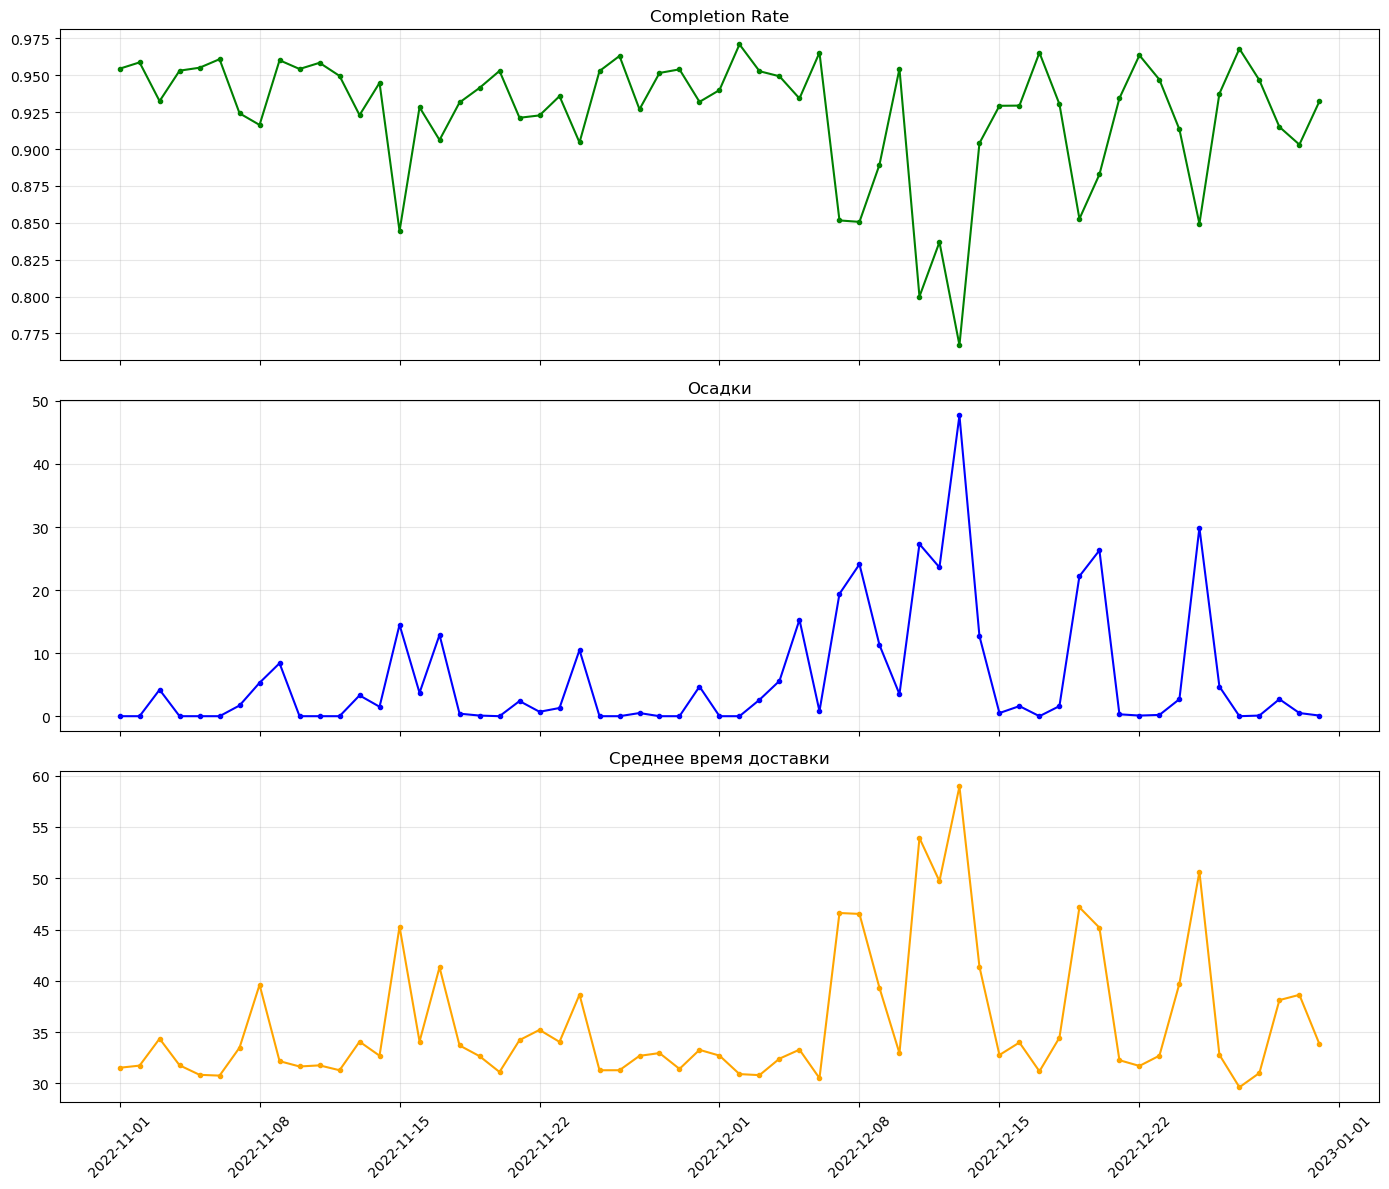

Топ-5 дней по осадкам:
          date  precipitation  completion_rate  avg_delivery_time
42  2022-12-13           47.7         0.767072          58.949268
54  2022-12-25           29.9         0.849378          50.635929
40  2022-12-11           27.3         0.800000          53.922492
49  2022-12-20           26.3         0.882773          45.176905
37  2022-12-08           24.1         0.850610          46.520669


In [11]:
# your code is here
daily['date'] = pd.to_datetime(daily['date']).dt.date
df_weather['date'] = pd.to_datetime(df_weather['date']).dt.date
merged = daily.merge(df_weather, on='date', how='left')
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
axes[0].plot(merged['date'], merged['completion_rate'], color='green', marker='.')
axes[0].set_title('Completion Rate')
axes[0].grid(True, alpha=0.3)
ax2 = axes[1]
ax2.plot(merged['date'], merged['precipitation'], color='blue', marker='.', label='Осадки (мм)')
ax2.set_title('Осадки')
ax2.grid(True, alpha=0.3)
ax3 = axes[2]
ax3.plot(merged['date'], merged['avg_delivery_time'], color='orange', marker='.', label='Время доставки (мин)')
ax3.set_title('Среднее время доставки')
ax3.grid(True, alpha=0.3)
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
print("Топ-5 дней по осадкам:")
print(merged.sort_values('precipitation', ascending=False)[['date', 'precipitation', 'completion_rate', 'avg_delivery_time']].head())

## Вывод 1.6.1.7

Вау вот это да, в наши аномальные дни бюыла штормовая погода, неудивительно, что произошел аномальный всплеск отмены заказов и увелечения времени доставки, кстати, если посмотреть внимательнее, в той мини аномалии, также ужасная погода :) 

#### 8. Влияние на бизнес-результат — 3 балла
Примените один из методов декомпозиции из разобранных в первом семинаре, чтобы оценить вклад изменения конверсии и числа заказов в изменение числа доставок в декабре относительно ноября (MoM анализ).    

Постройте waterfall диаграмму.

Выпишите дни, которые внесли наибольший вклад в падение среднемесячной конверсии декабря относительно ноября. Пересекаются ли эти даты с датами повышенного числа осадков? Сделайте выводы.

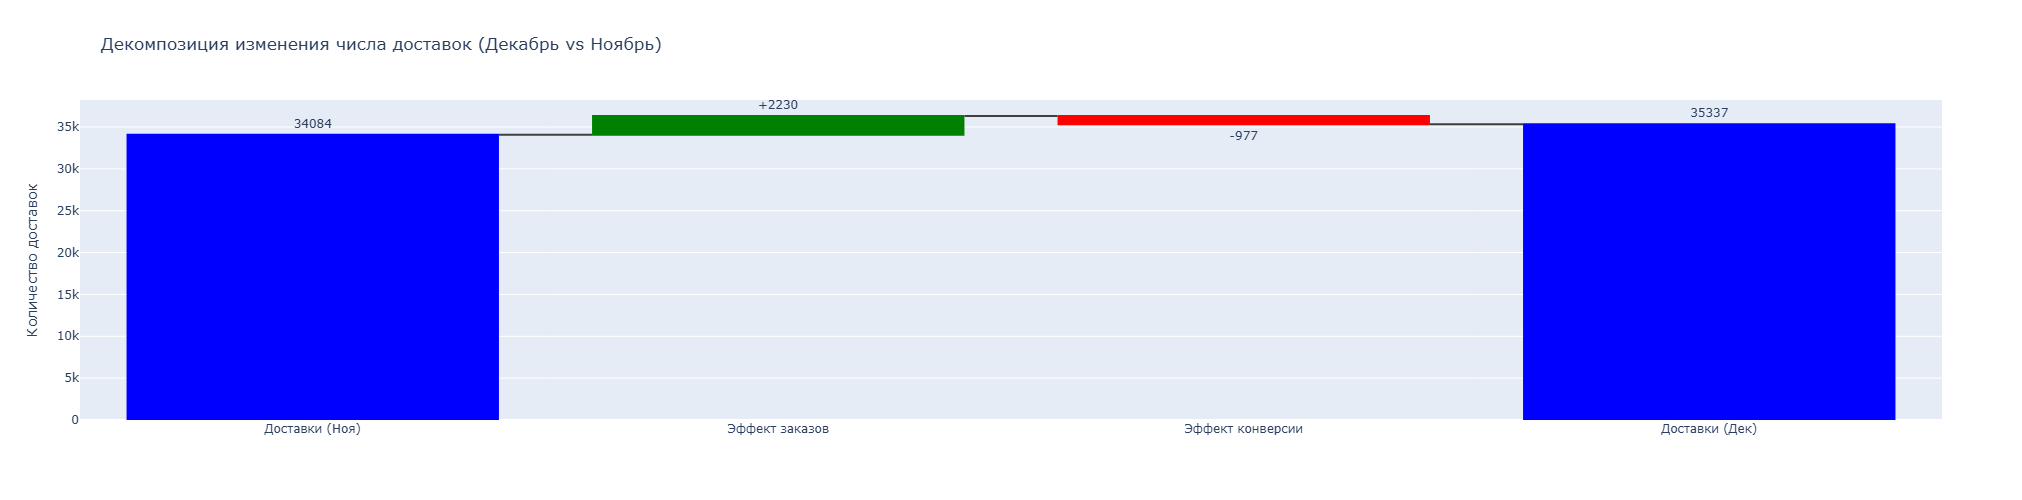

In [14]:
# your code is here
fig = go.Figure(go.Waterfall(
    name="MoM",
    orientation="v",
    measure=["absolute", "relative", "relative", "total"],
    x=["Доставки (Ноя)", "Эффект заказов", "Эффект конверсии", "Доставки (Дек)"],
    textposition="outside",
    text=["34084", "+2230", "-977", "35337"],
    y=[nov['delivered_orders'], delta_orders * nov['conversion'], dec['total_orders'] * delta_conv, dec['delivered_orders']],
    connector={"line": {"color": "rgb(63, 63, 63)"}},
    increasing={"marker": {"color": "green"}},
    decreasing={"marker": {"color": "red"}},
    totals={"marker": {"color": "blue"}}
))
fig.update_layout(
    title="Декомпозиция изменения числа доставок (Декабрь vs Ноябрь)",
    showlegend=False,
    yaxis_title="Количество доставок",
    width=800,
    height=500
)
fig.show()

In [15]:
nov_days = daily[daily['date'].apply(lambda x: x.month == 11)]
dec_days = daily[daily['date'].apply(lambda x: x.month == 12)]
avg_cr_nov = (nov_days['delivered_orders'].sum()) / (nov_days['total_orders'].sum())
dec_days = dec_days.copy()
dec_days['contribution'] = (dec_days['completion_rate'] - avg_cr_nov) * dec_days['total_orders']
worst_days = dec_days.sort_values('contribution').head(5)
print("Топ-5 дней с наибольшим отрицательным вкладом в падение CR:")
print(worst_days[['date', 'total_orders', 'completion_rate', 'contribution']])

Топ-5 дней с наибольшим отрицательным вкладом в падение CR:
          date  total_orders  completion_rate  contribution
40  2022-12-11          1595         0.800000   -221.300319
42  2022-12-13          1069         0.767072   -183.519775
54  2022-12-25          1527         0.849378   -136.465572
41  2022-12-12           889         0.836895    -90.545445
36  2022-12-07          1031         0.851600    -89.847417


####  9. Анализ 24/7 — 3 балла

Одним из распространенных разрезов анализа метрик продуктов с внутринедельной сезонностью является разложение по дням недели и часам. 

Постройте матрицу 24/7 (часы - дни недели) для ноября и декабря (в ячейку матрицы должно попасть агрегированное значение метрики для дня недели и часа), но перед этим очистите декабрьские значения от аномалий — для стабильной оценки нам нужны метрики без влияния экстремальной погоды.

Визуализацию стройте для:
- Числа заказов (всех);
- Completion Rate;
- Среднего или медианного времени доставки.

Подумайте, почему в определенные часы / дни недели мы наблюдаем падение конверсии? Как меняются остальные метрики?    
При ответе опирайтесь на статистические понятия — в какие-то часы просадка или, напротив, слишком высокая конверсия может быть не закономерностью, а случайностью из-за эффекта низкой базы в это время.

In [16]:
# your code is here
df['date'] = pd.to_datetime(df['order_time']).dt.date
bad_dates = [datetime(2022, 12, 9).date(), datetime(2022, 12, 10).date(), 
             datetime(2022, 12, 11).date(), datetime(2022, 12, 12).date(), 
             datetime(2022, 12, 13).date()]
df_clean = df[~df['date'].isin(bad_dates)].copy()
df_clean['hour'] = pd.to_datetime(df_clean['order_time']).dt.hour
df_clean['dayofweek'] = pd.to_datetime(df_clean['order_time']).dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_orders = df_clean.pivot_table(index='dayofweek', columns='hour', values='order_id', aggfunc='count', fill_value=0).reindex(days_order)
delivered_only = df_clean[df_clean['status'] == 'delivered']
pivot_cr = df_clean.groupby(['dayofweek', 'hour']).apply(lambda x: (x['status'] == 'delivered').mean()).unstack(fill_value=0).reindex(days_order)
pivot_time = delivered_only.pivot_table(index='dayofweek', columns='hour', values='delivery_time_min', aggfunc='median', fill_value=0).reindex(days_order)

C:\Users\Михаил\AppData\Local\Temp\ipykernel_18172\2958545271.py:12: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



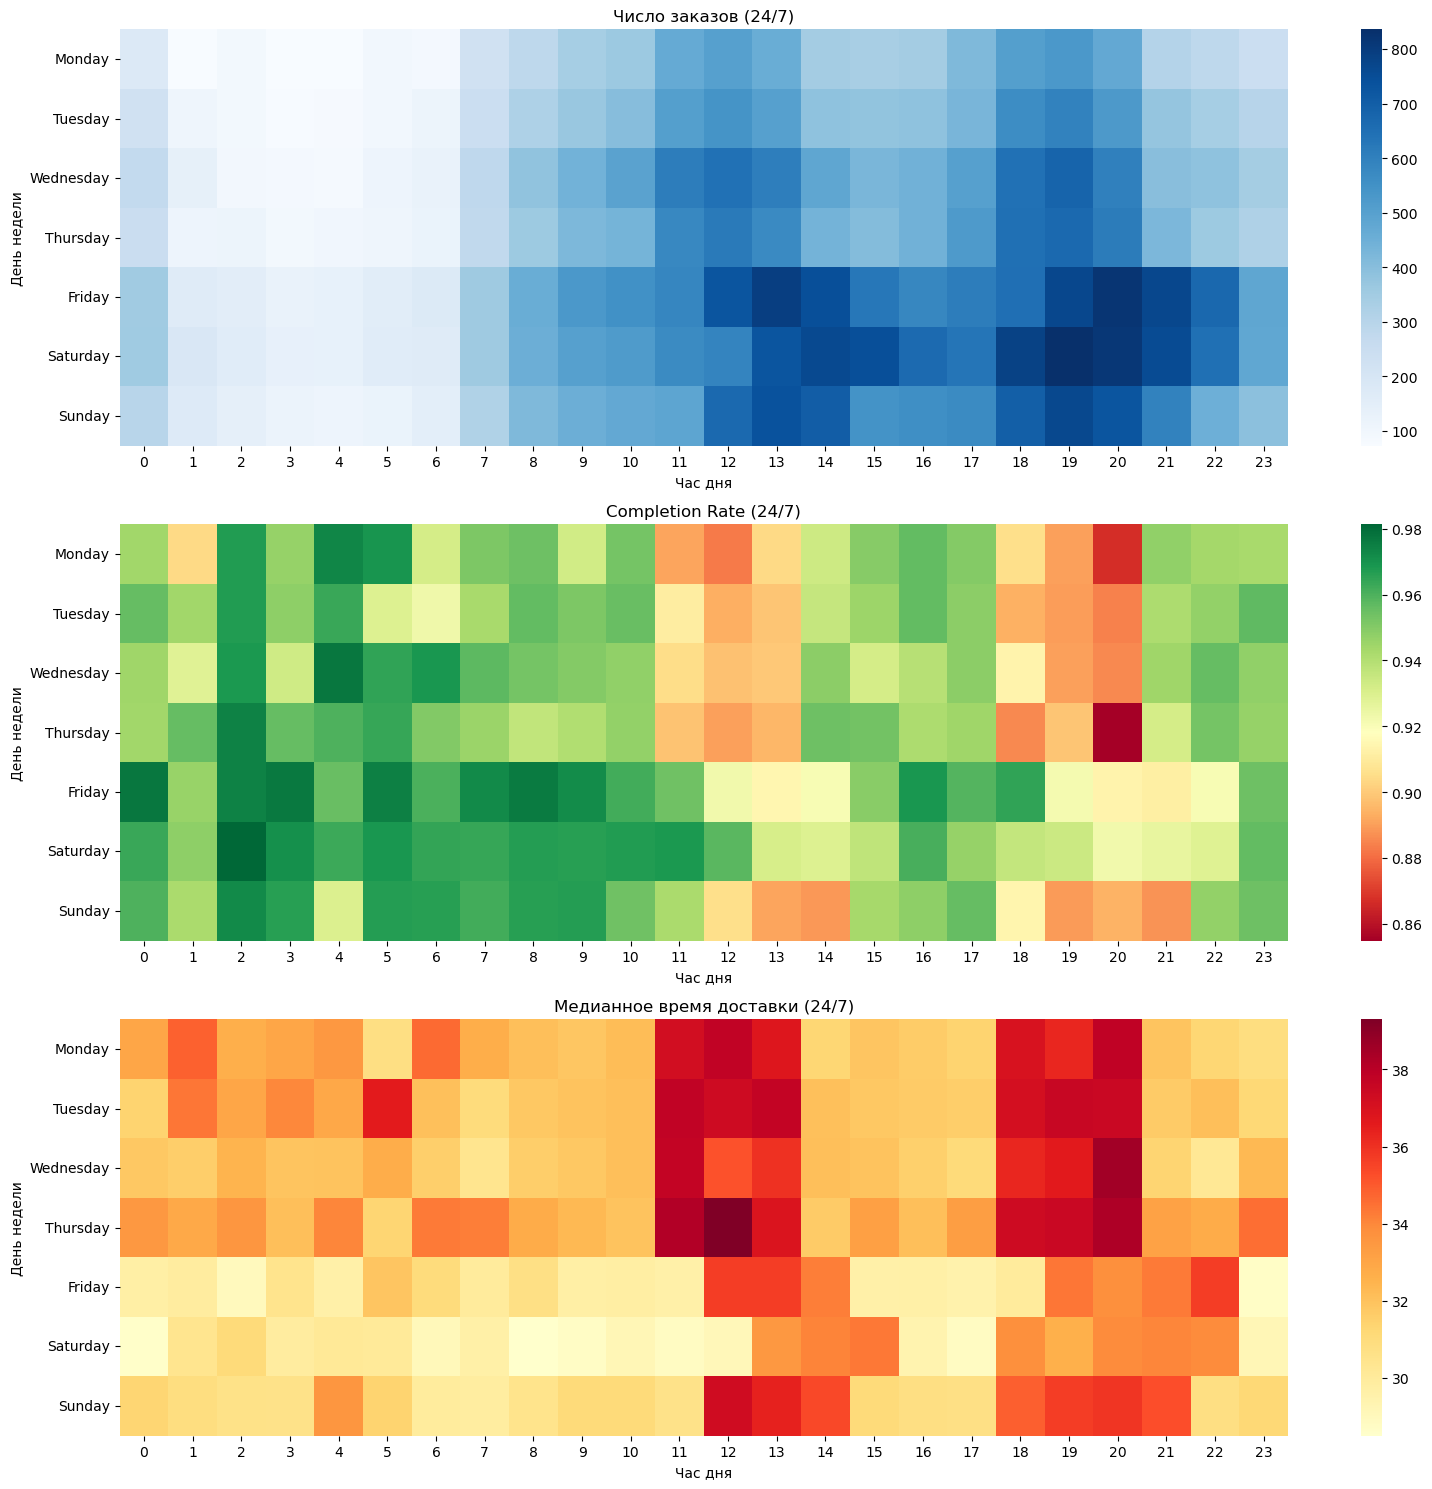

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(16, 15))
sns.heatmap(pivot_orders, cmap='Blues', ax=axes[0])
axes[0].set_title('Число заказов (24/7)')
sns.heatmap(pivot_cr, cmap='RdYlGn', ax=axes[1])
axes[1].set_title('Completion Rate (24/7)')
sns.heatmap(pivot_time, cmap='YlOrRd', ax=axes[2])
axes[2].set_title('Медианное время доставки (24/7)')
for ax in axes:
    ax.set_xlabel('Час дня')
    ax.set_ylabel('День недели')
plt.tight_layout()
plt.show()

## Выводы 1.9
Во первых, ка же я обожаю тепловаые карты, это чистая эстетика, а теперь по теме: 

1. Пик спроса - вечер будних и все выходные (вот это да :)))
2. Самые низкие значения конверсии (красные зоны) приходятся на вечерние часы (вот это неожиданно :)))
3. Конверсия типо высокая ночью, но опираться на это идиотизм, просто низкая выборка. 

# 10. Предложение по улучшению продукта — 3 балла
Базовым подходом для оптимизации работы в часы пик в доставке является динамическое ценообразование. В продукте эта механика еще не реализована. Вы смотрите на данные и решаете, что это отличная инициатива для планирования следующего квартала.

*Динамическое ценообразование помогает не только сглаживать часы повышенного спроса, но и регулировать работу продукта при внешних влияниях, когда пик спроса предсказать невозможно. В данном кейсе мы не рассматриваем такие решения, т.к. не стремимся написать алгоритм динамического прайсинга, а хотим провести базовое исследование проблем и поиск инициативы под быструю реализацию и тест. Поэтому в дальнейших заданиях речь идет исключительно о часах повышенного спроса, очищенных от аномалий.* 

Чтобы протестировать гипотезу, достаточно простого подхода — увеличивать стоимость доставки на фиксированный процент (например, на 20%) в определенные дни недели-часы.

- На основе построенных в предыдущем задании матриц, предложите, в какие дни недели / часы вы порекомендуете увеличить стоимость доставки.
- Для каждого месяца рассчитайте долю заказов от общего числа, который будет иметь повышенную стоимость, согласно предложенным вами правилам повышения.

In [18]:
# your code is here
df['dayofweek'] = pd.to_datetime(df['order_time']).dt.day_name()
df['hour'] = pd.to_datetime(df['order_time']).dt.hour
df['month'] = pd.to_datetime(df['order_time']).dt.to_period('M')
weekdays = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
weekends = ['Saturday', 'Sunday']
def is_peak(row):
    if row['dayofweek'] in weekdays and 18 <= row['hour'] <= 21:
        return True
    if row['dayofweek'] in weekends and 12 <= row['hour'] <= 22:
        return True
    return False
df['is_peak'] = df.apply(is_peak, axis=1)
share_nov = df[df['month'] == '2022-11']['is_peak'].mean()
share_dec = df[df['month'] == '2022-12']['is_peak'].mean()
print(f"Доля заказов с наценкой в ноябре: {share_nov:.2%}")
print(f"Доля заказов с наценкой в декабре: {share_dec:.2%}")

Доля заказов с наценкой в ноябре: 38.71%
Доля заказов с наценкой в декабре: 40.19%


## Предложения. 

1. Самое логичное для такого бизнеса вводить наценку в 20% в часы максимальной загрузки, выходные, вечер будних дней. Доля заказов с повышенной стоимостью в ноябре составила бы 38%, в декабре 40%, это ощутимая часть, которая способно повысить доходность компании на 8% (20% * 40%), что как бы не хухры мухры ;) 

### Часть 2. Дизайн эксперимента

Ваше предложение понравилось команде. Бэклог инициатив собран, время планировать роадмап. Вас просят провести дизайн эксперимента повышения стоимости доставки на 20% в регулярные часы повышенного спроса, чтобы команда поняла, сколько времени понадобится для получения результатов.

#### 1. Формат эксперимента — 3 балла

Выберите и обоснуйте единицу рандомизации теста: 
- по-юзерный A/B тест,
- свитчбек по времени (например, 30-минутки);
- региональный A/B тест.

Вы отвечали на тестовый вопрос о такой же инициативе в ДЗ 3, возможно, это поможет определиться.

Я считаю, что лушчее доказательство, это цифры (код ниже) 
Как мы видим в буднии дни идет лютейший перегруз работников компании как пример - в пиковые часы число заказов увеличивается в 2 раза, что приводит к росту времени доставки и падению Completion Rate. За счёт предложенного динамического ценообразования мы сможем сбалансировать кол-во заказов и их стоимость. Мы останемся при своём, но качество (скорость) доставки увеличится, мы банально получим лояльность наших пользователей, за потерю 10% заказов в пиковое время (имхо, по моей практике увеличение цены влечет за собой 10% снижение), плюч самое простое, вводим тестовый период нашего ноу-хау, смотрим, думаем, смотрим, думаем. 

In [22]:
df_clean = df[~df['date'].isin(bad_dates)].copy()
df_clean['hour'] = pd.to_datetime(df_clean['order_time']).dt.hour
df_clean['dayofweek'] = pd.to_datetime(df_clean['order_time']).dt.day_name()
stats = df_clean.groupby(['dayofweek', 'hour']).agg(
    orders=('order_id', 'count'),
    cr=('status', lambda x: (x == 'delivered').mean()),
    delivery_time=('delivery_time_min', 'median')
).reset_index()
weekdays = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
peak_weekdays = stats[(stats['dayofweek'].isin(weekdays)) & (stats['hour'].between(18, 21))]
offpeak_weekdays = stats[(stats['dayofweek'].isin(weekdays)) & (~stats['hour'].between(18, 21))]
weekends = ['Saturday', 'Sunday']
peak_weekends = stats[(stats['dayofweek'].isin(weekends)) & (stats['hour'].between(12, 22))]
offpeak_weekends = stats[(stats['dayofweek'].isin(weekends)) & (~stats['hour'].between(12, 22))]
print("Будни (18:00-21:00) vs Будни (остальное время):")
print(f"  Средний CR в пик: {peak_weekdays['cr'].mean():.3f} | вне пика: {offpeak_weekdays['cr'].mean():.3f}")
print(f"  Среднее время в пик: {peak_weekdays['delivery_time'].mean():.1f} мин | вне пика: {offpeak_weekdays['delivery_time'].mean():.1f} мин")
print(f"  Среднее число заказов в час в пик: {peak_weekdays['orders'].mean():.0f} | вне пика: {offpeak_weekdays['orders'].mean():.0f}")
print()
print("Выходные (12:00-22:00) vs Выходные (остальное время):")
print(f"  Средний CR в пик: {peak_weekends['cr'].mean():.3f} | вне пика: {offpeak_weekends['cr'].mean():.3f}")
print(f"  Среднее время в пик: {peak_weekends['delivery_time'].mean():.1f} мин | вне пика: {offpeak_weekends['delivery_time'].mean():.1f} мин")
print(f"  Среднее число заказов в час в пик: {peak_weekends['orders'].mean():.0f} | вне пика: {offpeak_weekends['orders'].mean():.0f}")

Будни (18:00-21:00) vs Будни (остальное время):
  Средний CR в пик: 0.907 | вне пика: 0.944
  Среднее время в пик: 35.4 мин | вне пика: 32.7 мин
  Среднее число заказов в час в пик: 578 | вне пика: 338

Выходные (12:00-22:00) vs Выходные (остальное время):
  Средний CR в пик: 0.926 | вне пика: 0.961
  Среднее время в пик: 33.3 мин | вне пика: 30.2 мин
  Среднее число заказов в час в пик: 681 | вне пика: 302


#### 2. Выбор таргет метрики — 3 балла

H1: Если мы введем динамическую наценку на доставку 20% в часы пик, то Completion Rate вырастет на 2%, а среднее время доставки снизится на 5%, потому что часть пользователей отложит заказ (снижение спроса), а повышенная оплата привлечет больше курьеров на линию (рост предложения).

Предложите таргет-метрику для эксперимента, обоснуйте свой выбор.

*Поскольку в гипотезе упоминаются сразу 2 метрики, и ни одна из них не является guardrail, метрику, которую вы не посчитаете таргетной, все равно будем учитывать в эксперименте как вторичную для принятия решения о результатах.*

Достаточно очевидно, что в качетве таргет-метрики необходимо брать Completion Rate

ОБОСНУЮ

Completion Rate напрямую отражает, сколько заказов компания смогла довезти и получить за них выручку. Выручка - наши денюжки, все хотят 100000000 не работая, внедряя наценки на свою продукцию, именно поэтому отмена заказа для нашей компании - потеря наших денег. Рост CR на 2% означает спасение части заказов, которые иначе были бы отменены и мы бы потеряли свои яндекс комиссионные .хых. 


#### 3. Выбор guardrails метрик — 3 балла

Выберите не более 3 guardrails-метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Guardrails метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

Зачем вы сдесь сделали код, я устал менять на марк(даун). Ладно, теперь серьезно (нет). 

Я бы взял следующие метрики: 

1. Доля отмен заказов по причине No courier available. Самое очевидно, мы стремимся уменьшить загруз курьеров для максимизации нашей прибыли (больше свободных курьеров, больше доставок, больше чеков, больше денег нам, вот это даааа). Если кол-во курьеров не выростет, что странно, значит внедряемая нами мера - полная фигня. ибо мы не получили больше заказов, а потеряли незначительное кол-во клиентов, которые не стали заказывать из-за повышения цены.
2. Средняя стоимость доставки. Наценка 20% напрямую влияет на этот показатель, если он не выростет, то мы тотально ошиблись и не компенсировали уход 2-3% клиентов повышением цены доставки.
3. Средний чек. Важно проверить, не начали ли пользователи экономить на еде, ибо это также наш доход, если люди берут меньше, мы получим меньше денег. (В данном случае могу привести также инновационную систему яндекс лавки, прогрессивная шкала стоимости доставки, когда от 100000000 рублей, доставка стоит на 30 рублей дешевле, и ты добиваешь корзину, чтобы не платить деньги вникуда, ибо товар пользователь воспринимает, как физический объект, который принадлежит тебе, а доставка, это эфимерная жертва корпорации, которую очень не хочется платить) 

#### 4. Выбор информативных метрик — 3 балла

Выберите не более 3 информативных метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Информативных метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

Поехали: 
1. Доля отмен заказов по причине «Cancelled by user». Показывает, не начали ли пользователи отменять заказы из-за высокой стоимости доставки. Если доля будет высокой, стоит задуматься о корректировке наценки или внедрении прогрессивной шкалы.
2. Среднее gross revenue на заказ (average order value + delivery fee). Позволяет оценить, не «съела» ли наценка выручку. Опять же нам важна прибыль, мы тут только ради прибыли, если мы стали получать меньше денег, значит инициатива 1. Недаработанная, 2. Бессмысленная.
3. Среднее время на поиск курьера. Это то зачем мы ввели повышение цены доставки, чем больше свободных курьеров и меньше время доставки, тем больше заказов будет доставлено. 

#### 5. Поправка на множественное сравнение — 3 балла

Перед тем, как приступить к расчету длительности, выберите уровень значимости и мощность, которые будете использовать в расчетах далее. Отталкивайтесь от общепринятых alpha = 0.05 и beta = 0.2.

Для поправки на множественное сравнение можете взять поправку Бонферрони. Не забывайте, что мы корректируем alpha только на число метрик, непосредственно участвующих в принятии решения об успешности теста.

Их было 4-веро 4-е пацана, ой, их было 3-и, 3-и метрики (а дальше рифму подбирайте сами) 

1. Таргет - Completion Rate.
2. Вторичная метрика - Среднее время доставки.
3. Guardrails: доля отмен по причине «No courier available», средняя стоимость доставки, средний чек.

- Изначальный уровень значимости: alpha = 0.05
- Мощность: 1 - beta = 0.8 (то есть beta = 0.2).
- Поправка Бонферрони: alpha_adj = 0.05 / 5 = 0.01

Итог: Для всех расчетов длительности эксперимента и MDE используем скорректированный уровень значимости alpha = 0.01 и мощность 0.8.


#### 6. Влияние выбросов на длительность эксперимента — 3 балла

В исследовательской части мы обнаружили аномальные значения метрик, вызванные внешними факторами. Такое состояние продукта не является целевым и случается достаточно редко.

На примере таргет метрики оцените дисперсию метрики, рассчитанную на значениях декабря полностью и с исключением аномального дня. Для исключения можете использовать **один** из подходов: удалить аномальный день или заменить его на другой не аномальный. Обоснуйте свой выбор.

Мы проводим эти расчеты в рамках дизайна эксперимента, поэтому в анализе используйте формулу (подсказки по формулам в задании ниже), которую будете применять для расчета длительности (ratio метрика, рассчитанная по единице рандомизации эксперимента).

Сделайте выводы о вариативности метрики при включении / исключении аномалии. Напишите, как разные подходы повлияют на длительность эксперимента и почему. Примите решение, какой из способов расчета будете применять вы в следующих шагах.

In [23]:
# your code is here

dec_days = daily[daily['date'].apply(lambda x: x.month == 12)].copy()
anomaly_date = datetime(2022, 12, 13).date()
dec_clean = dec_days[dec_days['date'] != anomaly_date].copy()
def calc_ratio_variance(df):
    X = df['delivered_orders'].sum()
    Y = df['total_orders'].sum()
    mean_Y = df['total_orders'].mean()
    mean_X = df['delivered_orders'].mean()
    var_X = df['delivered_orders'].var()
    var_Y = df['total_orders'].var()
    cov_XY = df[['delivered_orders', 'total_orders']].cov().iloc[0, 1]
    var_ratio = (1 / mean_Y**2) * var_X + (mean_X**2 / mean_Y**4) * var_Y - 2 * (mean_X / mean_Y**3) * cov_XY
    return var_ratio
var_with = calc_ratio_variance(dec_days)
var_without = calc_ratio_variance(dec_clean)
print(f"Дисперсия CR (с аномалией): {var_with:.6f}")
print(f"Дисперсия CR (без аномалии): {var_without:.6f}")
print(f"Отношение: {var_with / var_without:.2f}")

Дисперсия CR (с аномалией): 0.002733
Дисперсия CR (без аномалии): 0.002238
Отношение: 1.22


Вывод: 

Аномалия адски влияет, целых 22%, что как бы ооооочень много. Очевидно, что такое влияние надо исключать, 1-н аномальный день, не должен влиять на глобальных ход проводимого нами расчёта. 

#### 7. Длительность эксперимента — 3 балла

Рассчитайте длительность теста для выбранных таргет и вторичной метрик принятия решений. 

Обратите внимание, что обе метрики — ratio, используйте подходы для работы с данным типом метрик.

---
**Формулы расчета объёма выборки через MDE для разных метрик**

**Для среднего**

$$
n \;=\; \frac{2\,\sigma^2 \,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$


**Для доли** (бинарная метрика)

$$
n \;\\=\;\; \frac{2\,p(1-p)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для Ratio-метрики дельта-методом**

$$
\mathrm{Var}\!\left(\tfrac{X}{Y}\right) \;\approx\; 
\frac{1}{\mu_Y^2}\,\mathrm{Var}(X) 
\;+\; \frac{\mu_X^2}{\mu_Y^4}\,\mathrm{Var}(Y) 
\;-\; 2\,\frac{\mu_X}{\mu_Y^3}\,\mathrm{Cov}(X,Y)
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}\!\left(\tfrac{X}{Y}\right)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для линеаризованной Ratio-метрики**   
Переходим для каждой единицы рандомизации к линеаризованной версии метрики:

$$
Z_i \;=\; \frac{\overline X}{\overline Y} \;+\; \frac{1}{\overline Y}\!\left( X_i \;-\; \frac{\overline X}{\overline Y}\, Y_i \right).
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}(Z)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}.
$$


Для всех способов:
- Формулы указаны для групп одинакового размера (50/50) и двустороннего критерия;
- n — размер одной группы.

In [27]:
alpha_adj = 0.01
beta = 0.2
z_alpha = norm.ppf(1 - alpha_adj / 2)
z_beta = norm.ppf(1 - beta)
multiplier = 2 * (z_alpha + z_beta) ** 2
def get_ratio_variance(df, x_col, y_col):
    mean_X = df[x_col].mean()
    mean_Y = df[y_col].mean()
    var_X = df[x_col].var()
    var_Y = df[y_col].var()
    cov_XY = df[[x_col, y_col]].cov().iloc[0, 1]
    return (1 / mean_Y**2) * var_X + (mean_X**2 / mean_Y**4) * var_Y - 2 * (mean_X / mean_Y**3) * cov_XY
dec_clean = daily[daily['date'].apply(lambda x: x.month == 12) & (daily['date'] != datetime(2022, 12, 13).date())].copy()
dec_clean['total_orders'] = dec_clean['total_orders']
var_cr = get_ratio_variance(dec_clean, 'delivered_orders', 'total_orders')
mde_cr = 0.02
n_cr = (multiplier * var_cr) / (mde_cr ** 2)
deliv_clean = dec_clean.dropna(subset=['avg_delivery_time'])
var_time = get_ratio_variance(deliv_clean, 'avg_delivery_time', 'total_orders')
mde_time = 0.05 * deliv_clean['avg_delivery_time'].mean()
n_time = (multiplier * var_time) / (mde_time ** 2)
print(f"Размер выборки для CR (n на группу): {int(np.ceil(n_cr))}")

Размер выборки для CR (n на группу): 131


In [26]:
# your code is here
deliv_clean = dec_clean.dropna(subset=['avg_delivery_time'])
var_time = deliv_clean['avg_delivery_time'].var()
mean_time = deliv_clean['avg_delivery_time'].mean()
mde_time = 0.05 * mean_time
n_time = (2 * var_time * (z_alpha + z_beta)**2) / (mde_time**2)
print(f"Среднее время доставки: {mean_time:.2f} мин")
print(f"Дисперсия времени доставки: {var_time:.2f}")
print(f"MDE (5% от среднего): {mde_time:.2f} мин")
print(f"Размер выборки для времени доставки (n на группу): {int(np.ceil(n_time))}")

Среднее время доставки: 37.22 мин
Дисперсия времени доставки: 50.49
MDE (5% от среднего): 1.86 мин
Размер выборки для времени доставки (n на группу): 341


Для времени доставки (MDE = 5%): необходимо 341 единица на группу.
Для Completion Rate (MDE = 2%): необходимо 131 единица на группу.

Перевод в дни: При условии, что тест проводится только в часы пик (40% времени суток) и единица рандомизации — 30-минутки (48 единиц в сутки), длительность теста составит:
- При непрерывном тесте: 7.1 дня.
- При тесте только в часы пик: 17.8 дней.
- Округляем вверх до кратного 7 дням (из-за недельной сезонности): 21 день.

Вывод: Для получения результатов эксперимента потребуется около 3 недель.

#### 8. MDE для guardrails метрик — 3 балла

У нас нет информации по допустимым отрицательным эффектам для выбранных guardrails метрик, поступим обратным образом — рассчитайте минимальный детектируемый эффект для guardrails-метрик, используя максимальную длительность, полученную на предыдущем шаге (число дней целое и должно быть кратно 7 из-за недельной сезонности продукта). 

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [28]:
# your code is here
days = 21
units_per_day = 48
share_peak = 0.40
units_per_group = int(days * units_per_day * share_peak)
print(f"Количество единиц на группу за {days} дней: {units_per_group}")

Количество единиц на группу за 21 дней: 403


In [30]:
df['date'] = pd.to_datetime(df['order_time']).dt.date
anomaly_date = datetime(2022, 12, 13).date()
df_dec = df[(pd.to_datetime(df['order_time']).dt.month == 12) & (df['date'] != anomaly_date)].copy()
df_dec['no_courier_flag'] = (df_dec['status'] == 'cancelled') & (df_dec['cancellation_reason'] == 'No courier available')
mean_nc, rel_nc = get_mde_mean(df_dec['no_courier_flag'].astype(float), units_per_group)
print(f"No courier available: MDE = {mean_nc:.4f}, относительный MDE = {rel_nc:.2%}")
mean_fee, rel_fee = get_mde_mean(df_dec['delivery_fee'], units_per_group)
print(f"Средняя стоимость доставки: MDE = {mean_fee:.2f}, относительный MDE = {rel_fee:.2%}")
mean_check, rel_check = get_mde_mean(df_dec['order_value'], units_per_group)
print(f"Средний чек: MDE = {mean_check:.2f}, относительный MDE = {rel_check:.2%}")

No courier available: MDE = 0.0407, относительный MDE = 138.39%
Средняя стоимость доставки: MDE = 0.37, относительный MDE = 15.59%
Средний чек: MDE = 1.88, относительный MDE = 7.48%


1. Для «Средней стоимости доставки» и «Среднего чека» тест обладает достаточной чувствительностью: мы сможем заметить изменения в 7-15%, что является реалистичным для нашего эксперимента (наценка 20% должна дать заметный сдвиг).
2. Для «No courier available» MDE оказался очень высоким (138%). Это означает, что тест не сможет зафиксировать умеренный рост этой метрики. Однако, поскольку это guardrail, мы в первую очередь следим за тем, чтобы она не выросла катастрофически. Если она вырастет в 2 раза — мы это увидим.

#### 9. MDE для информативных метрик — 3 балла

Рассчитайте MDE для выбранных информативных метрик также, как рассчитывали для guardrails.

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [31]:
# your code is here
df_dec['gross_revenue'] = df_dec['order_value'] + df_dec['delivery_fee']
df_dec['cancelled_by_user_flag'] = (df_dec['status'] == 'cancelled') & (df_dec['cancellation_reason'] == 'Cancelled by user')
mean_assign, rel_assign = get_mde_mean(df_dec['time_to_assign_courier_min'], units_per_group)
print(f"Время на поиск курьера: MDE = {mean_assign:.2f} мин, относительный MDE = {rel_assign:.2%}")
mean_gross, rel_gross = get_mde_mean(df_dec['gross_revenue'], units_per_group)
print(f"Gross revenue на заказ: MDE = {mean_gross:.2f}, относительный MDE = {rel_gross:.2%}")
mean_cancel_user, rel_cancel_user = get_mde_mean(df_dec['cancelled_by_user_flag'].astype(float), units_per_group)
print(f"Отмены пользователем: MDE = {mean_cancel_user:.4f}, относительный MDE = {rel_cancel_user:.2%}")

Время на поиск курьера: MDE = 0.79 мин, относительный MDE = 10.36%
Gross revenue на заказ: MDE = 1.91, относительный MDE = 6.96%
Отмены пользователем: MDE = 0.0539, относительный MDE = 101.78%


#### 10. Правило принятия решения — 3 балла

Сформулируйте условия, при которых эксперимент считается успешным. Ваш ответ должен учитывать таргет-метрику, вторичную и guardrails.

Мы разбирали возможные варианты принятия решения об успешности в Лекции 3, можете использовать идеи оттуда.

Эксперимент считается успешным, если выполняются следующие условия:
1. Таргет-метрика (Completion Rate): Зафиксирован статистически значимый рост Completion Rate (p-value < 0.01 с учетом поправки Бонферрони) и он составляет не менее 2%.
2. Вторичная метрика (Среднее время доставки): Зафиксировано статистически значимое снижение. Среднего времени доставки (p-value < 0.01) и оно составляет не менее 5%.
3. Guardrails-метрики:
- Доля отмен по причине «No courier available» - не выросла статистически значимо (p-value < 0.01). Рост этой метрики означает, что курьеров всё равно не хватает, и наценка не решила проблему.
- Средняя стоимость доставки - рост ожидаем (наценка 20%), но он не должен привести к катастрофическому падению спроса. Мы смотрим на динамику заказов: если общее число заказов не упало более чем на 5%, это приемлемо.
- Средний чек - не должен значимо упасть (p-value < 0.01). Если пользователи стали экономить на еде, чтобы компенсировать дорогую доставку, это негативный сигнал.

Если хотя бы одно из условий не выполняется — эксперимент считается неуспешным, и мы либо откатываем изменение, либо дорабатываем гипотезу.